# MP1 — Divisão Treino/Teste e Análise Exploratória (EDA)

**Entrada:** `data/processed/base_limpa.csv` (gerado pelo Notebook 01).  
**Saída:** `data/processed/base_particionada.csv` (consumido pelo Notebook 03).

## 1. Ambiente e carregamento da base

In [1]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split

REPO_URL = "https://github.com/Gagdm/previsao_de_evasao_de_clientes.git"

cwd = Path.cwd()
if (cwd / "config.py").exists():
    raiz = cwd
elif (cwd.parent / "config.py").exists():
    raiz = cwd.parent
else:
    raiz = Path("/content/previsao_de_evasao_de_clientes")
    if not raiz.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(raiz)], check=True)

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from config import (
    ALVO, BASE_LIMPA, BASE_PARTICIONADA, BINARIAS, CATEGORICAS,
    ID, NUMERICAS, RANDOM_STATE, TAMANHO_TESTE,
)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
print(f"Repositório: {raiz}")
print(f"Arquivo de entrada: {BASE_LIMPA}")
print(f"Partição: {int((1-TAMANHO_TESTE)*100)}% treino / {int(TAMANHO_TESTE*100)}% teste; seed={RANDOM_STATE}")

Repositório: /content/previsao_de_evasao_de_clientes
Arquivo de entrada: /content/previsao_de_evasao_de_clientes/data/processed/base_limpa.csv
Partição: 70% treino / 30% teste; seed=42


In [2]:
if not BASE_LIMPA.is_file():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {BASE_LIMPA}. "
    )

df = pd.read_csv(BASE_LIMPA)
colunas_esperadas = [ID, ALVO] + NUMERICAS + CATEGORICAS + BINARIAS
faltantes = sorted(set(colunas_esperadas) - set(df.columns))
if faltantes:
    raise ValueError(f"Colunas necessárias não encontradas: {faltantes}")

if df[ID].isna().any() or df[ID].duplicated().any():
    raise ValueError("A base precisa ter identificadores de cliente únicos e válidos.")
if df[ALVO].isna().any() or not set(df[ALVO].unique()).issubset({0, 1}):
    raise ValueError("A variável churn deve ser binária (0/1) e não pode ter nulos.")
if df[ALVO].nunique() != 2:
    raise ValueError("As duas classes de churn devem estar presentes para a estratificação.")

print(f"Clientes: {len(df):,} | Colunas: {df.shape[1]}")
display(df.head())
print("Tipos das variáveis:")
display(df.dtypes.rename("tipo").to_frame())

Clientes: 4,976 | Colunas: 10


,id_cliente,tempo_cliente_meses,mensalidade_rs,chamados_totais,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,churn
0,C0001,29,67.96,2,0.0,Bienal,Boleto,0,0,0
1,C0002,19,65.95,0,0.0,Mensal,Cartão,0,0,0
2,C0003,18,100.88,1,1.0,Anual,Boleto,1,1,0
3,C0004,18,94.80,2,2.0,Mensal,Cartão,0,1,0
4,C0005,55,53.68,1,2.0,Anual,Pix,0,0,0


Tipos das variáveis:


,tipo
id_cliente,object
tempo_cliente_meses,int64
mensalidade_rs,float64
chamados_totais,int64
atrasos_6m,float64
tipo_contrato,object
forma_pagamento,object
fibra_optica,int64
debito_automatico,int64
churn,int64


## 2. Particionamento (70% / 30%)

A estratificação mantém a proporção aproximada de clientes que evadiram e permaneceram em ambos os conjuntos.

> Importante: após a divisão, toda investigação de padrões e escolha de tratamentos vai utilizar **apenas treino**. O teste ficará reservado para avaliação futura dos modelos.

In [3]:
COLUNA_PARTICAO = "split"
if COLUNA_PARTICAO in df.columns:
    raise ValueError(f"A coluna {COLUNA_PARTICAO!r} já existe na base de entrada.")

treino, teste = train_test_split(
    df,
    test_size=TAMANHO_TESTE,
    random_state=RANDOM_STATE,
    stratify=df[ALVO],
)
treino = treino.copy()
teste = teste.copy()
treino[COLUNA_PARTICAO] = "treino"
teste[COLUNA_PARTICAO] = "teste"

base_particionada = (
    pd.concat([treino, teste], ignore_index=True)
    .sort_values(ID, kind="stable")
    .reset_index(drop=True)
)

assert len(treino) + len(teste) == len(df)
assert set(treino[ID]).isdisjoint(set(teste[ID]))
assert base_particionada[ID].is_unique
assert not base_particionada[COLUNA_PARTICAO].isna().any()

print(f"Treino: {len(treino):,} linhas ({len(treino)/len(df):.1%})")
print(f"Teste:  {len(teste):,} linhas ({len(teste)/len(df):.1%})")

display(
    pd.DataFrame({
        "quantidade": [len(df), len(treino), len(teste)],
        "taxa_churn": [df[ALVO].mean(), treino[ALVO].mean(), teste[ALVO].mean()],
    }, index=["Total", "Treino", "Teste"]).style.format({"taxa_churn": "{:.2%}"})
)

Treino: 3,483 linhas (70.0%)
Teste:  1,493 linhas (30.0%)


,quantidade,taxa_churn
Total,4976,35.43%
Treino,3483,35.43%
Teste,1493,35.43%


## 3. Proporção de churn nos conjuntos


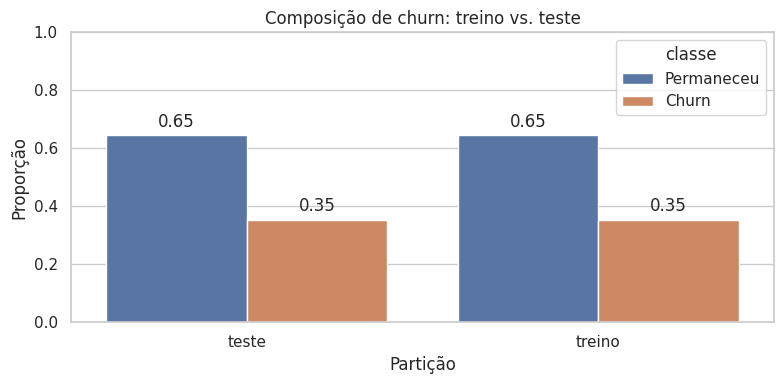

In [4]:
composicao = pd.concat([
    base_particionada.groupby(COLUNA_PARTICAO)[ALVO]
    .value_counts(normalize=True)
    .rename("proporcao")
    .reset_index(),
], ignore_index=True)
composicao["classe"] = composicao[ALVO].map({0: "Permaneceu", 1: "Churn"})

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=composicao, x=COLUNA_PARTICAO, y="proporcao", hue="classe")
ax.set(ylabel="Proporção", xlabel="Partição", title="Composição de churn: treino vs. teste", ylim=(0, 1))
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
plt.tight_layout()
plt.show()

## 4. Estatística descritiva do conjunto de treino

Analisamos o tamanho da amostra, classes, estatísticas das variáveis quantitativas e frequência das categorias.

In [9]:
print("Estatísticas descritivas — variáveis numéricas:")
display(treino[NUMERICAS].describe().T.round(2))

print("\nResumo das variáveis numéricas por classe de churn:")
display(treino.groupby(ALVO)[NUMERICAS].agg(["mean", "median", "std"]).round(2))

Estatísticas descritivas — variáveis numéricas:


,count,mean,std,min,25%,50%,75%,max
tempo_cliente_meses,3483.0,24.82,15.50,2.0,13.00,21.00,33.00,72.00
mensalidade_rs,3389.0,83.42,18.30,49.9,67.14,86.04,98.42,136.42
chamados_totais,3483.0,1.71,1.44,0.0,1.00,1.00,2.50,10.00
atrasos_6m,3452.0,1.04,0.95,0.0,0.00,1.00,2.00,5.00



Resumo das variáveis numéricas por classe de churn:


tempo_cliente_meses               mensalidade_rs                \
                     mean median    std           mean median    std   
churn                                                                  
0                   27.82   24.0  16.39          81.43  81.76  18.43   
1                   19.36   17.0  11.95          87.07  90.61  17.49   

      chamados_totais              atrasos_6m               
                 mean median   std       mean median   std  
churn                                                       
0                1.42    1.0  1.27       0.88    1.0  0.88  
1                2.23    2.0  1.58       1.33    1.0  1.01

In [8]:
for coluna in CATEGORICAS + BINARIAS:
    print(f"\nDistribuição — {coluna}:")
    frequencias = (
        treino[coluna]
        .value_counts(dropna=False)
        .rename_axis(coluna)
        .reset_index(name="quantidade")
    )
    frequencias["percentual"] = 100 * frequencias["quantidade"] / len(treino)
    display(frequencias.round(2))


Distribuição — tipo_contrato:


,tipo_contrato,quantidade,percentual
0,Mensal,1932,55.47
1,Anual,819,23.51
2,Bienal,715,20.53
3,NaN,17,0.49



Distribuição — forma_pagamento:


,forma_pagamento,quantidade,percentual
0,Boleto,1364,39.16
1,Cartão,1206,34.63
2,Pix,899,25.81
3,NaN,14,0.40



Distribuição — fibra_optica:


,fibra_optica,quantidade,percentual
0,1,1972,56.62
1,0,1511,43.38



Distribuição — debito_automatico:


,debito_automatico,quantidade,percentual
0,0,2116,60.75
1,1,1367,39.25


## 5. Dados ausentes

A base limpa ainda pode ter campos vazios. Aqui verificamos quantos são, sem alterar os dados.

,quantidade,percentual
mensalidade_rs,94,2.70
atrasos_6m,31,0.89
tipo_contrato,17,0.49
forma_pagamento,14,0.40
id_cliente,0,0.00
tempo_cliente_meses,0,0.00
chamados_totais,0,0.00
fibra_optica,0,0.00
debito_automatico,0,0.00
churn,0,0.00


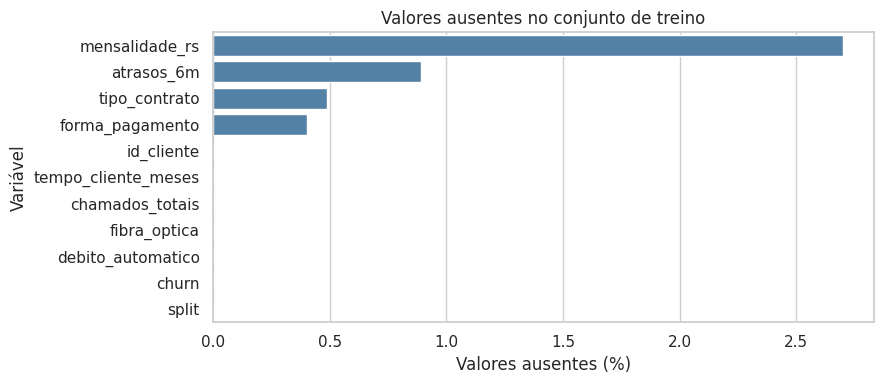

In [10]:
ausentes = treino.isna().sum().rename("quantidade").to_frame()
ausentes["percentual"] = 100 * ausentes["quantidade"] / len(treino)
ausentes = ausentes.sort_values("quantidade", ascending=False)
display(ausentes.round(2))

if ausentes["quantidade"].sum() == 0:
    print("Não há campos ausentes no treino.")
else:
    plt.figure(figsize=(9, 4))
    sns.barplot(data=ausentes.reset_index(), x="percentual", y="index", color="steelblue")
    plt.xlabel("Valores ausentes (%)")
    plt.ylabel("Variável")
    plt.title("Valores ausentes no conjunto de treino")
    plt.tight_layout()
    plt.show()

## 6. Distribuições das variáveis numéricas

Histogramas mostram a dispersão e a assimetria das variáveis. As curvas por classe ajudam a observar possíveis diferenças entre clientes com e sem churn, sem afirmar causalidade.

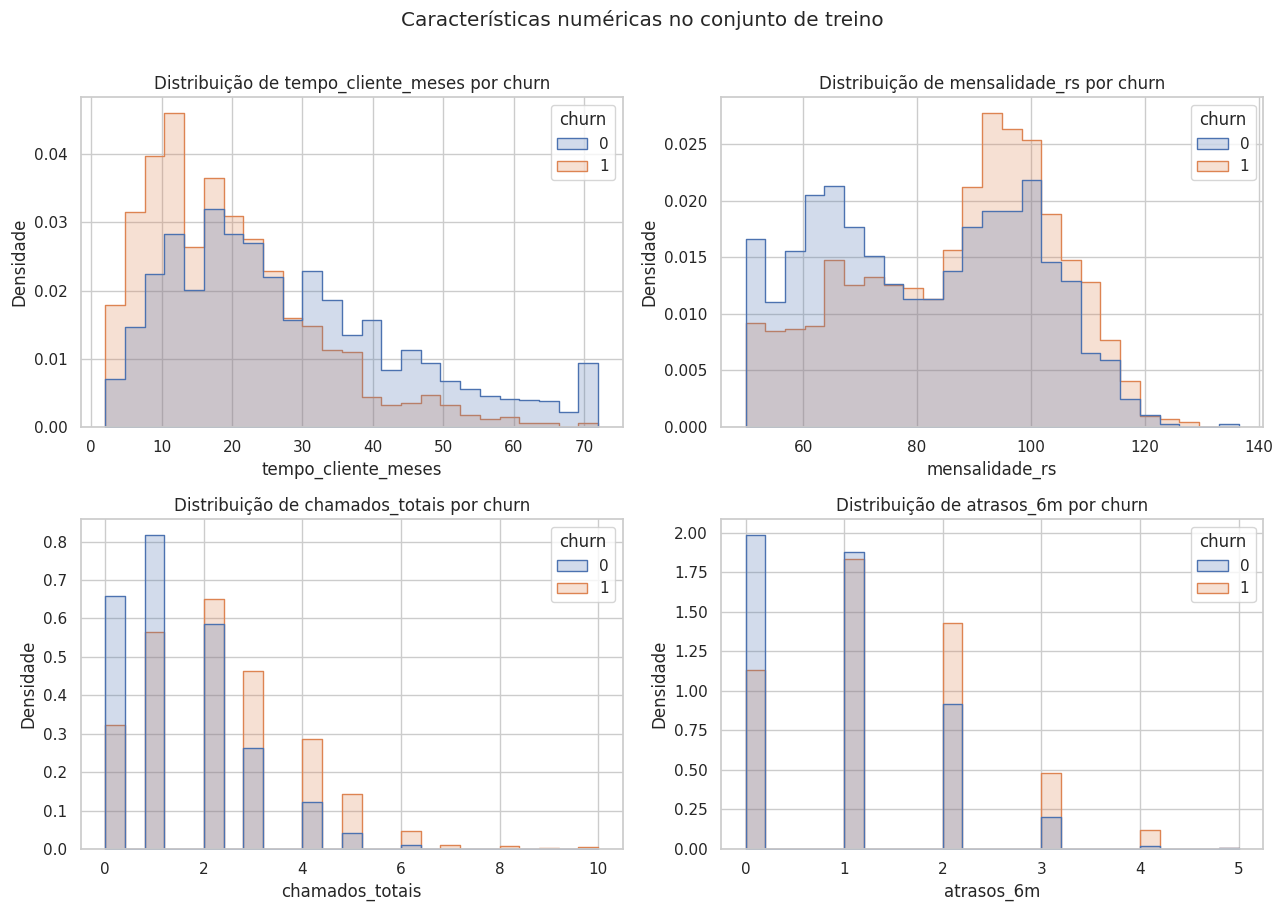

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, coluna in zip(axes.flat, NUMERICAS):
    sns.histplot(
        data=treino, x=coluna, hue=ALVO,
        bins=25, stat="density", common_norm=False,
        element="step", ax=ax,
    )
    ax.set_title(f"Distribuição de {coluna} por churn")
    ax.set_ylabel("Densidade")
plt.suptitle("Características numéricas no conjunto de treino", y=1.01)
plt.tight_layout()
plt.show()

## 7. Comparações por churn (boxplots)

Boxplots comparam mediana, dispersão e valores extremos das variáveis numéricas entre as classes.

/tmp/ipykernel_3299/2275547657.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Sem churn", "Com churn"])
/tmp/ipykernel_3299/2275547657.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Sem churn", "Com churn"])
/tmp/ipykernel_3299/2275547657.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Sem churn", "Com churn"])
/tmp/ipykernel_3299/2275547657.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Sem churn", "Com churn"])


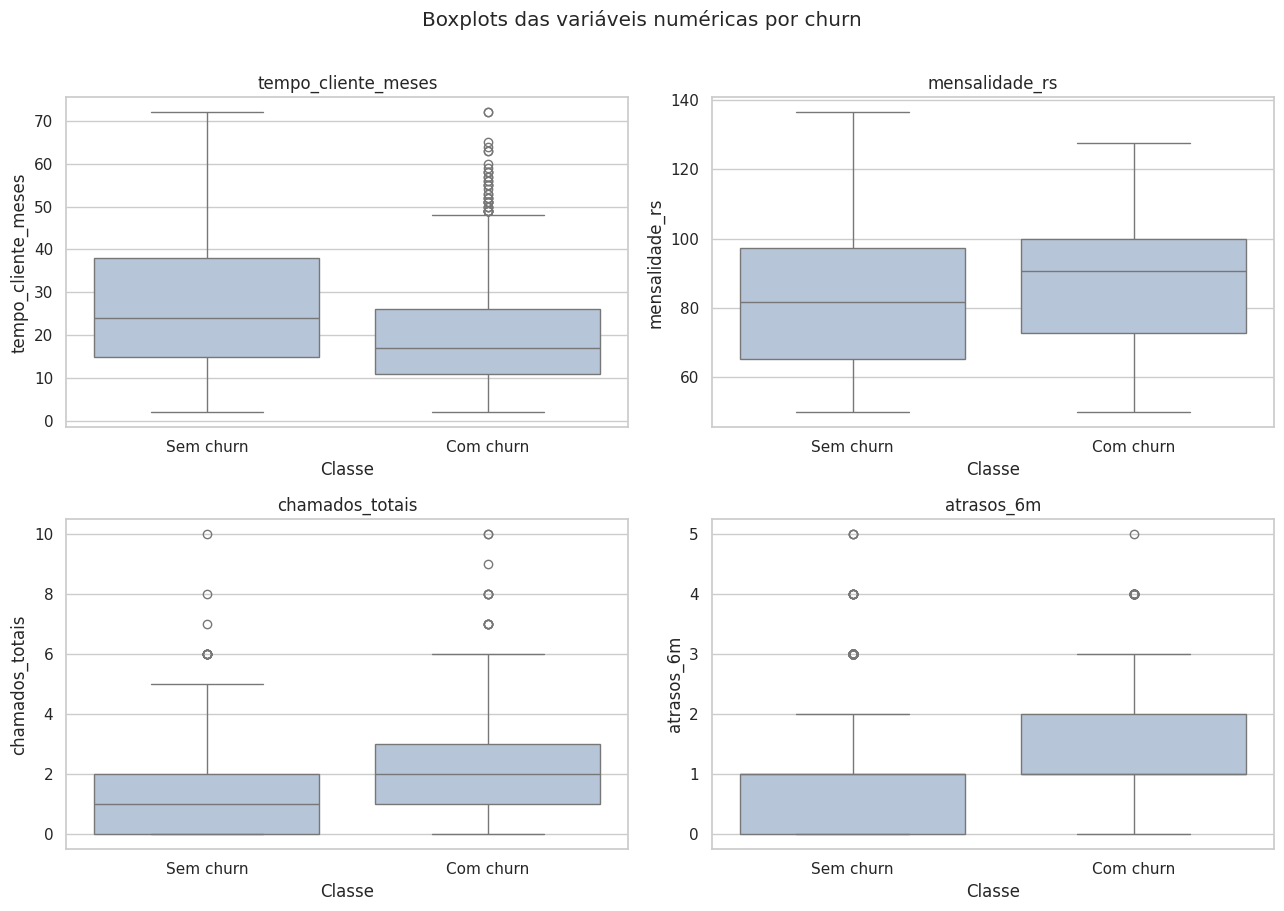

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, coluna in zip(axes.flat, NUMERICAS):
    sns.boxplot(data=treino, x=ALVO, y=coluna, ax=ax, color="lightsteelblue")
    ax.set_xticklabels(["Sem churn", "Com churn"])
    ax.set_xlabel("Classe")
    ax.set_title(coluna)
plt.suptitle("Boxplots das variáveis numéricas por churn", y=1.01)
plt.tight_layout()
plt.show()

## 8. Taxa de churn por tipo de contrato, pagamento e recursos binários

Para cada categoria, calculamos a taxa de churn (média de 0/1) e o número de observações. Grupos com poucas linhas precisam ser interpretados com cautela. Valores ausentes são omitidos das faixas e continuam no CSV final.


Churn por tipo_contrato:


,tipo_contrato,n_clientes,taxa_churn
2,Mensal,1932,46.69%
0,Anual,819,25.27%
1,Bienal,715,16.50%


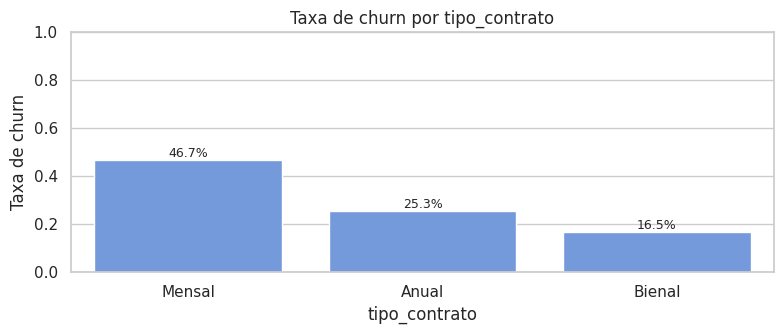


Churn por forma_pagamento:


,forma_pagamento,n_clientes,taxa_churn
2,Pix,899,36.15%
0,Boleto,1364,35.56%
1,Cartão,1206,34.58%


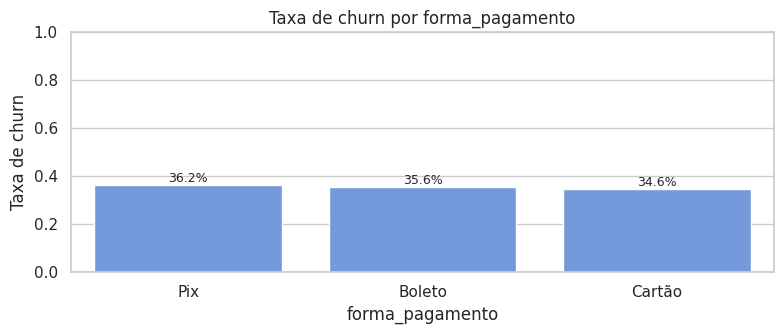


Churn por fibra_optica:


,fibra_optica,n_clientes,taxa_churn
1,1,1972,41.73%
0,0,1511,27.20%


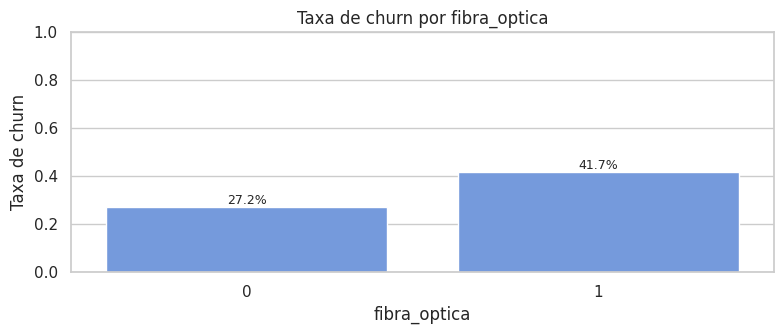


Churn por debito_automatico:


,debito_automatico,n_clientes,taxa_churn
0,0,2116,40.08%
1,1,1367,28.24%


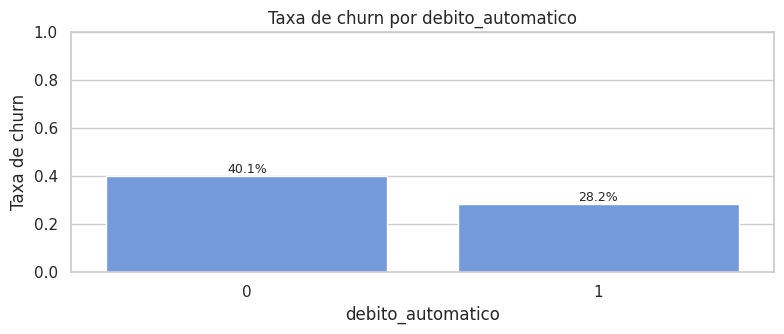

In [17]:
for coluna in CATEGORICAS + BINARIAS:
    taxas = (
        treino.groupby(coluna)[ALVO]
        .agg(n_clientes="size", taxa_churn="mean")
        .reset_index()
        .sort_values("taxa_churn", ascending=False)
    )
    print(f"\nChurn por {coluna}:")
    display(taxas.style.format({"taxa_churn": "{:.2%}"}))

    plt.figure(figsize=(8, 3.5))
    ax = sns.barplot(data=taxas, x=coluna, y="taxa_churn", color="cornflowerblue")
    ax.set(ylabel="Taxa de churn", xlabel=coluna, title=f"Taxa de churn por {coluna}", ylim=(0, 1))
    for barra in ax.patches:
        ax.annotate(f"{barra.get_height():.1%}",
                    (barra.get_x() + barra.get_width()/2, barra.get_height()),
                    ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.show()

## 9. Churn por faixas de variáveis numéricas

Agrupar números em quartis pode tornar diferenças mais legíveis. Essas faixas são apenas exploratórias, calculadas a partir do treino; não são adicionadas à base particionada. Valores ausentes são omitidos das faixas e continuam no CSV final.


Churn por quartis de tempo_cliente_meses:


,faixa,n_clientes,taxa_churn
0,"(1.999, 13.0]",922,50.65%
1,"(13.0, 21.0]",829,39.08%
2,"(21.0, 33.0]",892,33.52%
3,"(33.0, 72.0]",840,17.14%


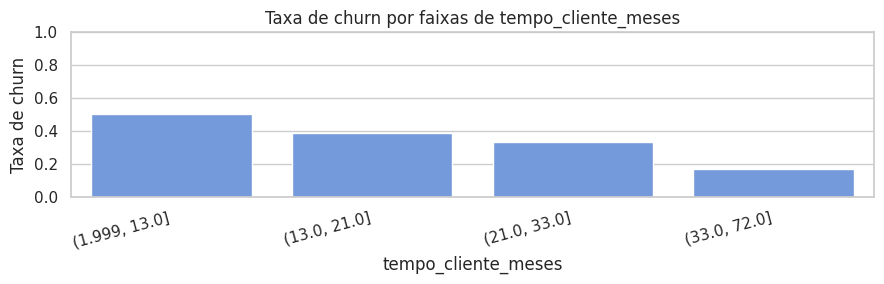


Churn por quartis de mensalidade_rs:


,faixa,n_clientes,taxa_churn
0,"(49.899, 67.14]",849,24.15%
1,"(67.14, 86.04]",846,33.92%
2,"(86.04, 98.42]",847,41.20%
3,"(98.42, 136.42]",847,41.91%


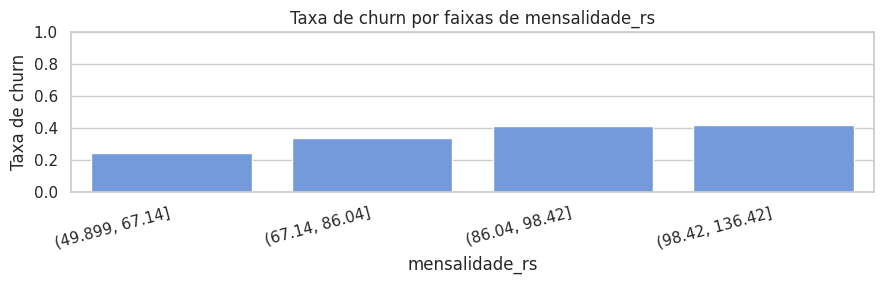


Churn por quartis de chamados_totais:


,faixa,n_clientes,taxa_churn
0,"(-0.001, 1.0]",1765,24.82%
1,"(1.0, 2.5]",847,37.90%
2,"(2.5, 10.0]",871,54.54%


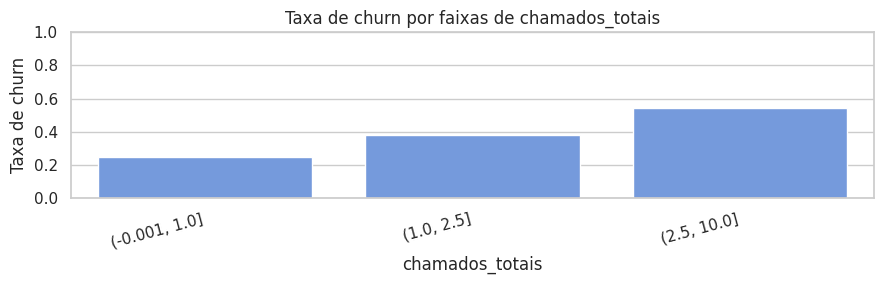


Churn por quartis de atrasos_6m:


,faixa,n_clientes,taxa_churn
0,"(-0.001, 1.0]",2445,29.78%
1,"(1.0, 2.0]",758,46.31%
2,"(2.0, 5.0]",249,59.44%


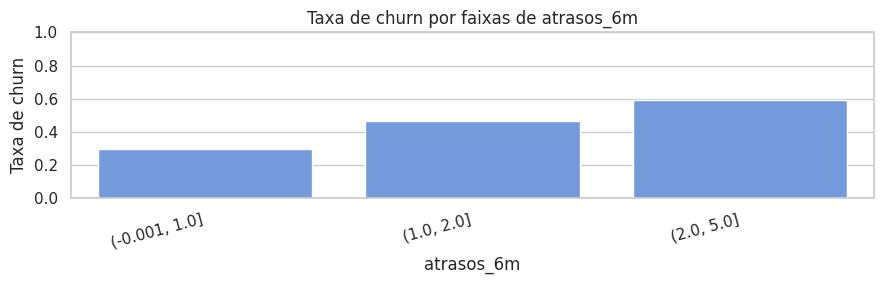

In [15]:
for coluna in NUMERICAS:
    serie = treino[coluna]
    try:
        faixas = pd.qcut(serie, q=4, duplicates="drop")
    except ValueError:
        print(f"Não foi possível criar faixas para {coluna} (valores insuficientes).")
        continue
    agrupado = (
        treino.assign(faixa=faixas)
        .groupby("faixa", observed=True)[ALVO]
        .agg(n_clientes="size", taxa_churn="mean")
        .reset_index()
    )
    if agrupado.empty:
        continue
    agrupado["faixa"] = agrupado["faixa"].astype(str)
    print(f"\nChurn por quartis de {coluna}:")
    display(agrupado.style.format({"taxa_churn": "{:.2%}"}))
    plt.figure(figsize=(9, 3))
    sns.barplot(data=agrupado, x="faixa", y="taxa_churn", color="cornflowerblue")
    plt.title(f"Taxa de churn por faixas de {coluna}")
    plt.ylabel("Taxa de churn")
    plt.xlabel(coluna)
    plt.xticks(rotation=15, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

## 10. Correlações entre variáveis numéricas

Usamos correlação de Pearson para identificar associações lineares, incluindo as variáveis binárias e o alvo. Correlação **não implica causalidade**, e uma correlação fraca não descarta uma relação não linear com o churn.

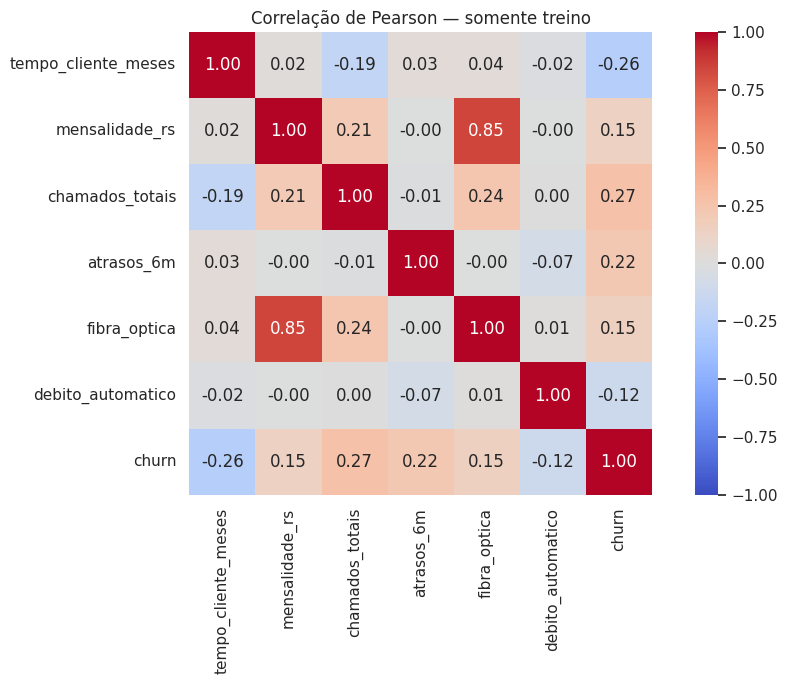

Correlação com churn (ordenada):


,correlacao_com_churn
chamados_totais,0.268340
atrasos_6m,0.222170
fibra_optica,0.150595
mensalidade_rs,0.147286
debito_automatico,-0.120862
tempo_cliente_meses,-0.260951


In [14]:
colunas_corr = NUMERICAS + BINARIAS + [ALVO]
correlacoes = treino[colunas_corr].corr(method="pearson")

plt.figure(figsize=(10, 7))
sns.heatmap(correlacoes, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True)
plt.title("Correlação de Pearson — somente treino")
plt.tight_layout()
plt.show()

print("Correlação com churn (ordenada):")
display(correlacoes[ALVO].drop(ALVO).sort_values(ascending=False).rename("correlacao_com_churn").to_frame())

## 11. Possíveis outliers

O critério interquartil (IQR) sinaliza observações fora de `[Q1 - 1,5 × IQR; Q3 + 1,5 × IQR]`. Em variáveis de contagem, esses valores podem ser legítimos, por isso não excluímos registros automaticamente.

In [13]:
resultado_outliers = []
for coluna in NUMERICAS:
    serie = treino[coluna].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    qtd = int(((serie < limite_inf) | (serie > limite_sup)).sum())
    resultado_outliers.append({
        "variavel": coluna,
        "limite_inferior": limite_inf,
        "limite_superior": limite_sup,
        "possiveis_outliers": qtd,
        "percentual_dos_validos": 100 * qtd / len(serie) if len(serie) else np.nan,
    })
display(pd.DataFrame(resultado_outliers).round(2))

,variavel,limite_inferior,limite_superior,possiveis_outliers,percentual_dos_validos
0,tempo_cliente_meses,-17.00,63.00,101,2.90
1,mensalidade_rs,20.22,145.34,0,0.00
2,chamados_totais,-1.25,4.75,154,4.42
3,atrasos_6m,-3.00,5.00,0,0.00


## 12. Exportação da base particionada

O CSV gerado mantém todas as colunas originais e valores faltantes, adicionando apenas `split`, com os valores `treino` ou `teste`.

In [18]:
BASE_PARTICIONADA.parent.mkdir(parents=True, exist_ok=True)
base_particionada.to_csv(BASE_PARTICIONADA, index=False, encoding="utf-8")

# Validação da exportação.
conferir = pd.read_csv(BASE_PARTICIONADA)
assert conferir.shape == base_particionada.shape
assert conferir[ID].is_unique
assert set(conferir[COLUNA_PARTICAO]) == {"treino", "teste"}
assert conferir[COLUNA_PARTICAO].value_counts().to_dict() == {
    "treino": len(treino), "teste": len(teste),
}

print(f"Arquivo gerado: {BASE_PARTICIONADA}")
print(f"Dimensão: {conferir.shape[0]} linhas × {conferir.shape[1]} colunas")

Arquivo gerado: /content/previsao_de_evasao_de_clientes/data/processed/base_particionada.csv
Dimensão: 4976 linhas × 11 colunas


In [19]:
try:
    from google.colab import files
    files.download(str(BASE_PARTICIONADA))
except ImportError:
    print(f"Execução local: CSV disponível em {BASE_PARTICIONADA}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>